# NGHIÊN CỨU & TRIỂN KHAI TOÀN DIỆN MÔ PHỎNG MONTE CARLO TRONG TÀI CHÍNH & QUẢN TRỊ DANH MỤC (PORTFOLIO MANAGEMENT)

> **Tài liệu tham chiếu gốc:** `H:\Portfolios_Management\Doc\Lab\lab9_monte_calo`  
> **Tác giả nghiên cứu:** Antigravity AI Assistant  
> **Mục tiêu:** Hệ thống hóa cơ chế toán học, tái lập và thực thi trọn vẹn 4 bài toán kinh điển trong Lab 9 (Dự báo Lợi nhuận gộp, Dự báo Giá cổ phiếu GBM, Định giá Black-Scholes-Merton, Rời rạc hóa Euler Monte Carlo) và mở rộng sang **Quản trị Danh mục Đầu tư Đa tài sản & Tối ưu hóa Markowitz**.

---

## 1. TỔNG QUAN & CƠ CHẾ NỀN TẢNG CỦA PHƯƠNG PHÁP MONTE CARLO

### 1.1 Khái niệm & Triết lý cốt lõi
**Mô phỏng Monte Carlo (Monte Carlo Simulation - MCS)** là một lớp thuật toán tính toán dựa trên việc lấy mẫu ngẫu nhiên lặp đi lặp lại để thu được các kết quả bằng số cho các bài toán mà việc tìm nghiệm giải tích (analytical closed-form solution) là bất khả thi hoặc quá phức tạp.

Bản chất toán học của Monte Carlo là **ước lượng tích phân kỳ vọng**:
$$\mathbb{E}[f(X)] = \int_{\Omega} f(x) p(x) \, dx \approx \frac{1}{M} \sum_{i=1}^M f\left(X^{(i)}\right)$$
trong đó:
- $X$ là biến ngẫu nhiên tuân theo phân phối xác suất có hàm mật độ $p(x)$.
- $X^{(i)}$ là các mẫu ngẫu nhiên độc lập cùng phân phối (i.i.d.) được rút ra từ phân phối $p(x)$.
- $M$ là số lượng kịch bản mô phỏng (iterations / simulations).

### 1.2 Hai định lý trụ cột bảo đảm tính hội tụ:
1. **Luật Số Lớn (Law of Large Numbers - LLN):**
   $$\lim_{M \to \infty} \frac{1}{M} \sum_{i=1}^M f\left(X^{(i)}\right) \xrightarrow{a.s.} \mathbb{E}[f(X)]$$
   Khi số lần mô phỏng $M$ tiến tới vô cùng, giá trị trung bình mẫu hội tụ hầu chắc chắn về giá trị kỳ vọng thực tế.
2. **Định lý Giới hạn Trung tâm (Central Limit Theorem - CLT):**
   Sai số ước lượng $\epsilon_M = \bar{f}_M - \mathbb{E}[f(X)]$ có phân phối tiệm cận chuẩn:
   $$\epsilon_M \sim \mathcal{N}\left(0, \frac{\sigma^2_f}{M}\right) \implies \text{Standard Error } (SE) = \frac{\sigma_f}{\sqrt{M}} = O\left(\frac{1}{\sqrt{M}}\right)$$
   *Điểm ưu việt tuyệt đối của Monte Carlo:* Tốc độ hội tụ $O(M^{-1/2})$ **hoàn toàn độc lập với số chiều của bài toán** ($d$). Trong khi các phương pháp lưới tích phân số học (numerical quadrature grid methods) bị "Lời nguyền số chiều" (Curse of Dimensionality: độ phức tạp $O(N^{-1/d})$), Monte Carlo xử lý các bài toán tài chính 10, 50 hay 100 tài sản với cùng tốc độ hội tụ!

---

### 1.3 Phân biệt rõ nét: Monte Carlo Simulation (MCS) vs Monte Carlo Tree Search (MCTS)
Trong bối cảnh tối ưu hóa danh mục đầu tư và lý thuyết trò chơi (Game Theory / PortfolioZero):

| Tiêu chí | Monte Carlo Simulation (MCS) | Monte Carlo Tree Search (MCTS) |
| :--- | :--- | :--- |
| **Bản chất** | Mô phỏng ngẫu nhiên các quá trình ngẫu nhiên liên tục (Stochastic Processes) | Thuật toán tìm kiếm cây quyết định tối ưu trong không gian rời rạc |
| **Không gian trạng thái** | Liên tục (Giá cổ phiếu $S_t \in \mathbb{R}^+$, Lợi nhuận $r_t \in \mathbb{R}$) | Rời rạc (Trạng thái bảng cờ, Các bước phân bổ tỷ trọng rời rạc) |
| **Cơ chế cốt lõi** | Lấy mẫu i.i.d. từ phân phối xác suất đã biết (Normal, Log-normal, Jump-diffusion) | 4 bước tuần hoàn: **Selection** (UCB1) $\to$ **Expansion** $\to$ **Simulation (Rollout)** $\to$ **Backpropagation** |
| **Vai trò của ngẫu nhiên** | Đo lường rủi ro, định giá kỳ vọng tích phân | Đánh giá giá trị của trạng thái lá thông qua mô phỏng ngẫu nhiên đến cuối ván |
| **Ứng dụng tiêu biểu** | Định giá quyền chọn (BSM, Euler), Tính VaR/CVaR, Dự báo giá tài sản | AlphaGo, Tối ưu danh mục bằng RL / Game Theory (PortfolioZero) |

> **Mối liên hệ tương hỗ:** Trong MCTS, bước **Simulation (Rollout)** thực chất chính là việc áp dụng một chính sách mô phỏng Monte Carlo để định giá trạng thái! Việc nắm vững bản chất MCS là tiền đề bắt buộc để hiểu sâu MCTS.

In [1]:
# Thiết lập môi trường thực thi và nạp các thư viện tài chính định lượng cốt lõi
import os
import tempfile
# Khắc phục quyền ghi cache của matplotlib trong môi trường sandbox Windows
os.environ['MPLCONFIGDIR'] = os.path.join(tempfile.gettempdir(), 'mpl_cache')

import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

# Cấu hình thẩm mỹ đồ họa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

# Khởi tạo seed để đảm bảo tính tái lập (reproducibility)
SEED = 42
np.random.seed(SEED)

print("✅ Đã nạp thành công các thư viện: NumPy", np.__version__, "| Pandas", pd.__version__)

✅ Đã nạp thành công các thư viện: NumPy 1.23.5 | Pandas 2.3.3


In [2]:
def load_market_data(filename, symbol_name):
    """
    Hàm tiện ích nạp dữ liệu chuỗi thời gian giá cổ phiếu từ các đường dẫn dự phòng:
    1. Thư mục cục bộ 'data/' trong Experiment
    2. Thư mục gốc Lab 9 'H:/Portfolios_Management/Doc/Lab/lab9_monte_calo/...'
    """
    candidates = [
        os.path.join(os.getcwd(), 'data', filename),
        os.path.join(os.path.dirname(os.getcwd()), 'Experiment', 'data', filename),
        os.path.join(r"H:\Portfolios_Management\Portfolios_Management_Theory_Games_Study\Experiment\data", filename),
        os.path.join(r"H:\Portfolios_Management\Doc\Lab\lab9_monte_calo\02_Monte Carlo - Predicting Stock Prices\csv", filename)
    ]
    for path in candidates:
        if os.path.exists(path):
            df = pd.read_csv(path, index_col='Date', parse_dates=True)
            print(f"✅ Đã nạp thành công dữ liệu {symbol_name} từ: {path} (Kích thước: {df.shape})")
            return df
    raise FileNotFoundError(f"❌ Không tìm thấy tệp {filename} trong các đường dẫn tìm kiếm.")

# Kiểm tra nạp thử dữ liệu PG và MSFT
df_pg_raw = load_market_data('PG_2007_2017.csv', 'Procter & Gamble (PG)')
df_msft_raw = load_market_data('MSFT_2000.csv', 'Microsoft (MSFT)')

✅ Đã nạp thành công dữ liệu Procter & Gamble (PG) từ: h:\Portfolios_Management\Portfolios_Management_Theory_Games_Study\Experiment\data\PG_2007_2017.csv (Kích thước: (2586, 1))
✅ Đã nạp thành công dữ liệu Microsoft (MSFT) từ: h:\Portfolios_Management\Portfolios_Management_Theory_Games_Study\Experiment\data\MSFT_2000.csv (Kích thước: (4479, 1))


---
## 2. PHẦN 1: DỰ BÁO LỢI NHUẬN GỘP DOANH NGHIỆP (PREDICTING GROSS PROFIT)

### 2.1 Bối cảnh & Cơ chế Tài chính
Trong hoạch định tài chính doanh nghiệp (Corporate Financial Planning), các chỉ tiêu tương lai không phải là các con số đơn trị cố định (deterministic) mà là các **biến ngẫu nhiên (random variables)** bị chi phối bởi điều kiện thị trường, lạm phát, chi phí nguyên vật liệu và sức mua của khách hàng.

Thay vì chỉ dự báo một kịch bản đơn giản (Point Estimate):
$$\text{Gross Profit} = \text{Revenue} - \text{COGS}$$
Phương pháp Monte Carlo cho phép mô hình hóa sự bất định đồng thời của cả Doanh thu và Chi phí:

1. **Doanh thu (Revenue - $Rev$):**
   $$Rev \sim \mathcal{N}\left(\mu_{rev}, \sigma_{rev}^2\right)$$
   Với $\mu_{rev}$ là doanh thu kỳ vọng và $\sigma_{rev}$ là độ biến động doanh thu do thị trường.

2. **Tỷ lệ Giá vốn Hàng bán (Cost of Goods Sold Ratio - $COGS_{\%}$):**
   $$COGS_{\%} \sim \mathcal{N}\left(\mu_{cogs}, \sigma_{cogs}^2\right)$$
   Với $\mu_{cogs}$ là tỷ lệ giá vốn bình quân (ví dụ $40\% - 60\%$) và $\sigma_{cogs}$ là độ bất định về biên chi phí.

3. **Giá vốn thực tế (COGS) & Lợi nhuận gộp (Gross Profit - $GP$):**
   $$COGS = - (Rev \times COGS_{\%})$$
   $$\text{Gross Profit} = Rev + COGS = Rev \times (1 - COGS_{\%})$$

> **Ý nghĩa:** Tích của hai biến ngẫu nhiên phân phối chuẩn tạo ra phân phối phức hợp có đuôi dày hơn phân phối chuẩn thông thường. Monte Carlo giúp xác định:
> - Phân phối xác suất thực tế của Lợi nhuận gộp.
> - Khả năng doanh nghiệp rơi vào tình trạng thua lỗ gộp ($P(GP < 0)$).
> - Ngưỡng rủi ro kịch bản xấu nhất (Value-at-Risk 5%).

In [3]:
def simulate_gross_profit(rev_mean, rev_std, cogs_mean, cogs_std, iterations=10000, random_seed=42):
    """
    Thực hiện mô phỏng Monte Carlo dự báo Lợi nhuận gộp doanh nghiệp.
    """
    np.random.seed(random_seed)
    # 1. Sinh ngẫu nhiên Doanh thu từ phân phối chuẩn
    rev = np.random.normal(loc=rev_mean, scale=rev_std, size=iterations)
    
    # 2. Sinh ngẫu nhiên tỷ lệ COGS
    cogs_ratio = np.random.normal(loc=cogs_mean, scale=cogs_std, size=iterations)
    # Ràng buộc tỷ lệ chi phí thực tế không âm
    cogs_ratio = np.clip(cogs_ratio, a_min=0.0, a_max=None)
    
    # 3. Tính COGS và Gross Profit
    cogs = - (rev * cogs_ratio)
    gross_profit = rev + cogs
    
    # 4. Thống kê kết quả
    stats = {
        "Mean (Kỳ vọng)": np.mean(gross_profit),
        "Std Dev (Độ rủi ro)": np.std(gross_profit),
        "Min (Tệ nhất)": np.min(gross_profit),
        "Max (Tốt nhất)": np.max(gross_profit),
        "Median (Trung vị)": np.median(gross_profit),
        "5% Percentile (VaR 95%)": np.percentile(gross_profit, 5),
        "95% Percentile": np.percentile(gross_profit, 95),
        "Prob of Loss (P(GP < 0))": np.mean(gross_profit < 0) * 100
    }
    return rev, cogs, gross_profit, stats

# Thực hiện mô phỏng theo 2 kịch bản của Lab 9:
# Kịch bản 1: Lecture (rev_m=170, rev_std=20, cogs_m=0.6, cogs_std=0.1)
rev_lec, cogs_lec, gp_lec, stats_lec = simulate_gross_profit(170, 20, 0.6, 0.1, iterations=10000)

# Kịch bản 2: Solution (rev_m=200, rev_std=10, cogs_m=0.4, cogs_std=0.2)
rev_sol, cogs_sol, gp_sol, stats_sol = simulate_gross_profit(200, 10, 0.4, 0.2, iterations=10000)

# Tổng hợp bảng so sánh kết quả
df_gp_comparison = pd.DataFrame([stats_lec, stats_sol], index=["Kịch bản Lecture (Rev=170)", "Kịch bản Solution (Rev=200)"])
df_gp_comparison

,Mean (Kỳ vọng),Std Dev (Độ rủi ro),Min (Tệ nhất),Max (Tốt nhất),Median (Trung vị),5% Percentile (VaR 95%),95% Percentile,Prob of Loss (P(GP < 0))
Kịch bản Lecture (Rev=170),67.770073,18.972855,-6.109333,154.566403,67.103209,37.824357,100.351419,0.01
Kịch bản Solution (Rev=200),119.083233,39.677032,-52.880375,228.242204,119.443607,53.011955,185.768201,0.13


💡 Nhận xét quản trị:
- Kịch bản 1: Lợi nhuận gộp kỳ vọng đạt 67.77 triệu $, với 95% tin cậy lợi nhuận không thấp hơn 37.82 triệu $.
- Kịch bản 2: Dù doanh thu cao hơn (200M), nhưng do độ biến động COGS lớn (0.2), phân phối trải rộng hơn đáng kể (Std: 39.68M so với 18.97M).


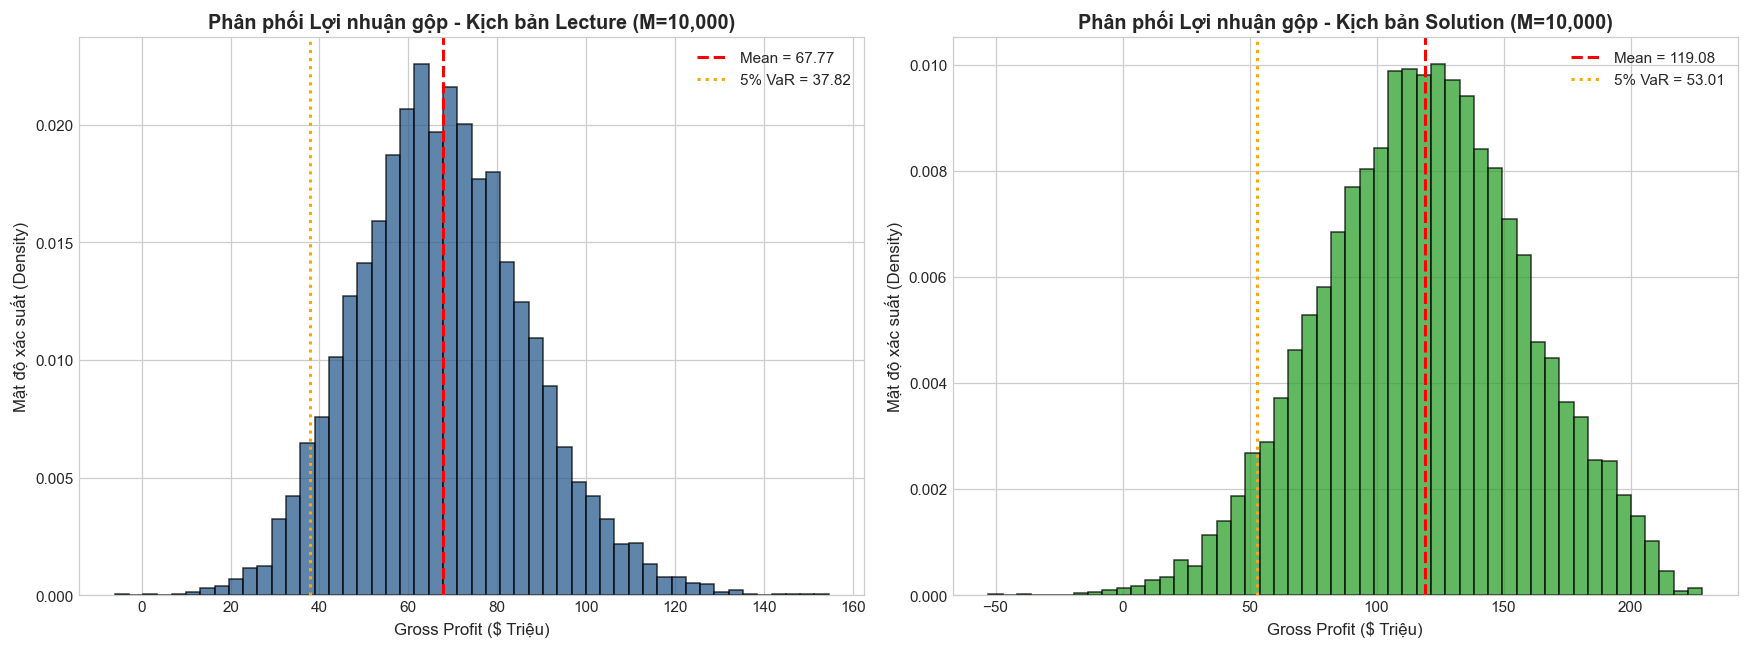

In [4]:
# Trực quan hóa phân phối kết quả dự báo Lợi nhuận gộp
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Đồ thị 1: Kịch bản Lecture
ax1 = axes[0]
n, bins, patches = ax1.hist(gp_lec, bins=50, color='#2b5c8f', alpha=0.75, edgecolor='black', density=True)
var_5_lec = stats_lec["5% Percentile (VaR 95%)"]
mean_lec = stats_lec["Mean (Kỳ vọng)"]
ax1.axvline(mean_lec, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_lec:.2f}')
ax1.axvline(var_5_lec, color='orange', linestyle=':', linewidth=2, label=f'5% VaR = {var_5_lec:.2f}')
ax1.set_title("Phân phối Lợi nhuận gộp - Kịch bản Lecture (M=10,000)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Gross Profit ($ Triệu)", fontsize=11)
ax1.set_ylabel("Mật độ xác suất (Density)", fontsize=11)
ax1.legend(loc='upper right')

# Đồ thị 2: Kịch bản Solution (Biến động COGS lớn hơn: std=0.2)
ax2 = axes[1]
ax2.hist(gp_sol, bins=50, color='#2ca02c', alpha=0.75, edgecolor='black', density=True)
var_5_sol = stats_sol["5% Percentile (VaR 95%)"]
mean_sol = stats_sol["Mean (Kỳ vọng)"]
ax2.axvline(mean_sol, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_sol:.2f}')
ax2.axvline(var_5_sol, color='orange', linestyle=':', linewidth=2, label=f'5% VaR = {var_5_sol:.2f}')
ax2.set_title("Phân phối Lợi nhuận gộp - Kịch bản Solution (M=10,000)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Gross Profit ($ Triệu)", fontsize=11)
ax2.set_ylabel("Mật độ xác suất (Density)", fontsize=11)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(f"💡 Nhận xét quản trị:")
print(f"- Kịch bản 1: Lợi nhuận gộp kỳ vọng đạt {stats_lec['Mean (Kỳ vọng)']:.2f} triệu $, với 95% tin cậy lợi nhuận không thấp hơn {var_5_lec:.2f} triệu $.")
print(f"- Kịch bản 2: Dù doanh thu cao hơn (200M), nhưng do độ biến động COGS lớn (0.2), phân phối trải rộng hơn đáng kể (Std: {stats_sol['Std Dev (Độ rủi ro)']:.2f}M so với {stats_lec['Std Dev (Độ rủi ro)']:.2f}M).")

---
## 3. PHẦN 2: DỰ BÁO GIÁ CỔ PHIẾU BẰNG CHUYỂN ĐỘNG BROWNIAN HÌNH HỌC (GBM)

### 3.1 Cơ sở Toán học của Geometric Brownian Motion (GBM)
Trong tài chính định lượng, chuyển động Brownian hình học (GBM) là mô hình chuẩn mực nhất mô tả quá trình giá cổ phiếu biến thiên liên tục theo thời gian, được khởi xướng bởi Louis Bachelier (1900) và hoàn thiện bởi Paul Samuelson (1965).

Phương trình vi phân ngẫu nhiên (Stochastic Differential Equation - SDE):
$$\frac{dS_t}{S_t} = \mu \, dt + \sigma \, dW_t \iff dS_t = \mu S_t \, dt + \sigma S_t \, dW_t$$
trong đó:
- $S_t$: Giá cổ phiếu tại thời điểm $t$.
- $\mu$: Suất sinh lời kỳ vọng hàng năm (Expected Return / Drift rate).
- $\sigma$: Độ biến động hàng năm của cổ phiếu (Volatility / Diffusion coefficient).
- $W_t$: Quá trình Wiener chuẩn (Chuẩn chuyển động Brownian) với $dW_t \sim \mathcal{N}(0, dt)$.

---

### 3.2 Bổ đề Itô & Bản chất Cực kỳ Quan trọng của "Drift Correction" ($-\frac{1}{2}\sigma^2$)
Xét hàm logarit của giá: $f(S_t) = \ln S_t$.  
Theo Bổ đề Itô (Itô's Lemma), do $(dW_t)^2 = dt \neq 0$:
$$d(\ln S_t) = \frac{\partial \ln S_t}{\partial S_t} dS_t + \frac{1}{2} \frac{\partial^2 \ln S_t}{\partial S_t^2} (dS_t)^2$$
$$= \frac{1}{S_t} \left(\mu S_t dt + \sigma S_t dW_t\right) + \frac{1}{2}\left(-\frac{1}{S_t^2}\right)\left(\sigma^2 S_t^2 dt\right)$$
$$\mathbf{d(\ln S_t) = \left(\mu - \frac{1}{2}\sigma^2\right)dt + \sigma \, dW_t}$$

#### 🔍 Tại sao bắt buộc phải trừ $\frac{1}{2}\sigma^2$? (Giải thích sâu cơ chế Lab 9)
Đây là câu hỏi cốt lõi mà nhiều nhà phân tích nhầm lẫn!
- Nếu $r = \ln(S_t / S_{t-1}) \sim \mathcal{N}(m, s^2)$, thì $S_t / S_{t-1} = e^r$ là một **biến ngẫu nhiên có phân phối Log-normal**.
- Theo tính chất hàm sinh mô-men (Moment Generating Function) hoặc **Bất đẳng thức Jensen**:
  $$\mathbb{E}\left[e^r\right] = \exp\left( \mathbb{E}[r] + \frac{1}{2}\text{Var}(r) \right) = \exp\left( m + \frac{1}{2}s^2 \right)$$
- Để tỷ suất tăng trưởng kỳ vọng của giá cổ phiếu đúng bằng $\mu$:
  $$\mathbb{E}\left[\frac{S_t}{S_0}\right] = e^{\mu t} \implies m + \frac{1}{2}s^2 = \mu t \implies m = \left(\mu - \frac{1}{2}\sigma^2\right)t$$
> **Kết luận:** Nếu chúng ta không trừ đi $\frac{1}{2}\sigma^2$ trong số hạng drift, mô phỏng giá sẽ bị **thổi phồng nhân tạo (overestimated / upward bias)** tỷ lệ thuận với độ biến động $\sigma^2$!

---

### 3.3 Công thức Lấy mẫu Rời rạc hóa (Discrete Step Simulation)
Đối với mỗi bước thời gian $\Delta t$ (ví dụ 1 ngày giao dịch):
$$\text{daily\_return}_t = \exp\left( \left(\mu - \frac{1}{2}\sigma^2\right)\Delta t + \sigma \sqrt{\Delta t} \, Z_t \right)$$
$$S_t = S_{t-1} \times \text{daily\_return}_t$$
trong đó $Z_t = \Phi^{-1}(U) \sim \mathcal{N}(0, 1)$ với $U \sim \mathcal{U}(0, 1)$ được tính thông qua hàm `scipy.stats.norm.ppf` (Percent Point Function / Inverse Cumulative Distribution Function).

In [5]:
def simulate_gbm_paths(price_series, t_intervals=250, iterations=1000, random_seed=42):
    """
    Mô phỏng các quỹ đạo giá tương lai theo chuyển động Brownian hình học (GBM).
    """
    np.random.seed(random_seed)
    
    # 1. Tính toán Log Returns hàng ngày
    log_returns = np.log(1 + price_series.pct_change().dropna())
    u = log_returns.mean()
    var = log_returns.var()
    stdev = log_returns.std()
    
    # 2. Tính Drift đã hiệu chỉnh và Volatility
    drift = u - (0.5 * var)
    
    # Ép kiểu vô hướng scalar float an toàn
    drift_val = float(drift.iloc[0] if isinstance(drift, pd.Series) else drift)
    stdev_val = float(stdev.iloc[0] if isinstance(stdev, pd.Series) else stdev)
    
    # 3. Tạo ma trận các cú sốc ngẫu nhiên chuẩn Z (t_intervals x iterations)
    # norm.ppf(np.random.rand(...)) tương đương chuẩn mực nhưng trực tiếp dùng standard_normal
    Z = norm.ppf(np.random.rand(t_intervals, iterations))
    daily_returns = np.exp(drift_val + stdev_val * Z)
    
    # 4. Tạo ma trận đường đi của giá (Price Matrix)
    price_paths = np.zeros_like(daily_returns)
    S0 = float(price_series.iloc[-1].iloc[0] if isinstance(price_series.iloc[-1], pd.Series) else price_series.iloc[-1])
    price_paths[0] = S0
    
    # Tích lũy giá qua từng ngày
    for t in range(1, t_intervals):
        price_paths[t] = price_paths[t - 1] * daily_returns[t]
        
    return {
        "S0": S0,
        "daily_u": drift_val + 0.5 * (stdev_val**2),
        "daily_drift": drift_val,
        "daily_stdev": stdev_val,
        "annual_stdev": stdev_val * np.sqrt(250),
        "price_paths": price_paths,
        "terminal_prices": price_paths[-1]
    }

# Thực thi mô phỏng trên dữ liệu cổ phiếu Proctor & Gamble (PG)
gbm_pg = simulate_gbm_paths(df_pg_raw[['PG']], t_intervals=250, iterations=1000)

print(f"--- THÔNG SỐ GBM CỦA PROCTER & GAMBLE (PG) ---")
print(f"Giá khởi điểm (S0): {gbm_pg['S0']:.4f} $")
print(f"Drift ngày: {gbm_pg['daily_drift']:.6f} | Volatility ngày: {gbm_pg['daily_stdev']:.6f}")
print(f"Volatility thường niên hóa (Annual Volatility): {gbm_pg['annual_stdev']*100:.2f}%")
print(f"Giá kỳ vọng sau 250 ngày: {np.mean(gbm_pg['terminal_prices']):.2f} $")
print(f"Giá trung vị sau 250 ngày: {np.median(gbm_pg['terminal_prices']):.2f} $")
print(f"Khoảng tin cậy 95% của giá S_T: [{np.percentile(gbm_pg['terminal_prices'], 2.5):.2f} $, {np.percentile(gbm_pg['terminal_prices'], 97.5):.2f} $]")

--- THÔNG SỐ GBM CỦA PROCTER & GAMBLE (PG) ---
Giá khởi điểm (S0): 88.1186 $
Drift ngày: 0.000182 | Volatility ngày: 0.011138
Volatility thường niên hóa (Annual Volatility): 17.61%
Giá kỳ vọng sau 250 ngày: 94.01 $
Giá trung vị sau 250 ngày: 92.72 $
Khoảng tin cậy 95% của giá S_T: [65.86 $, 131.19 $]


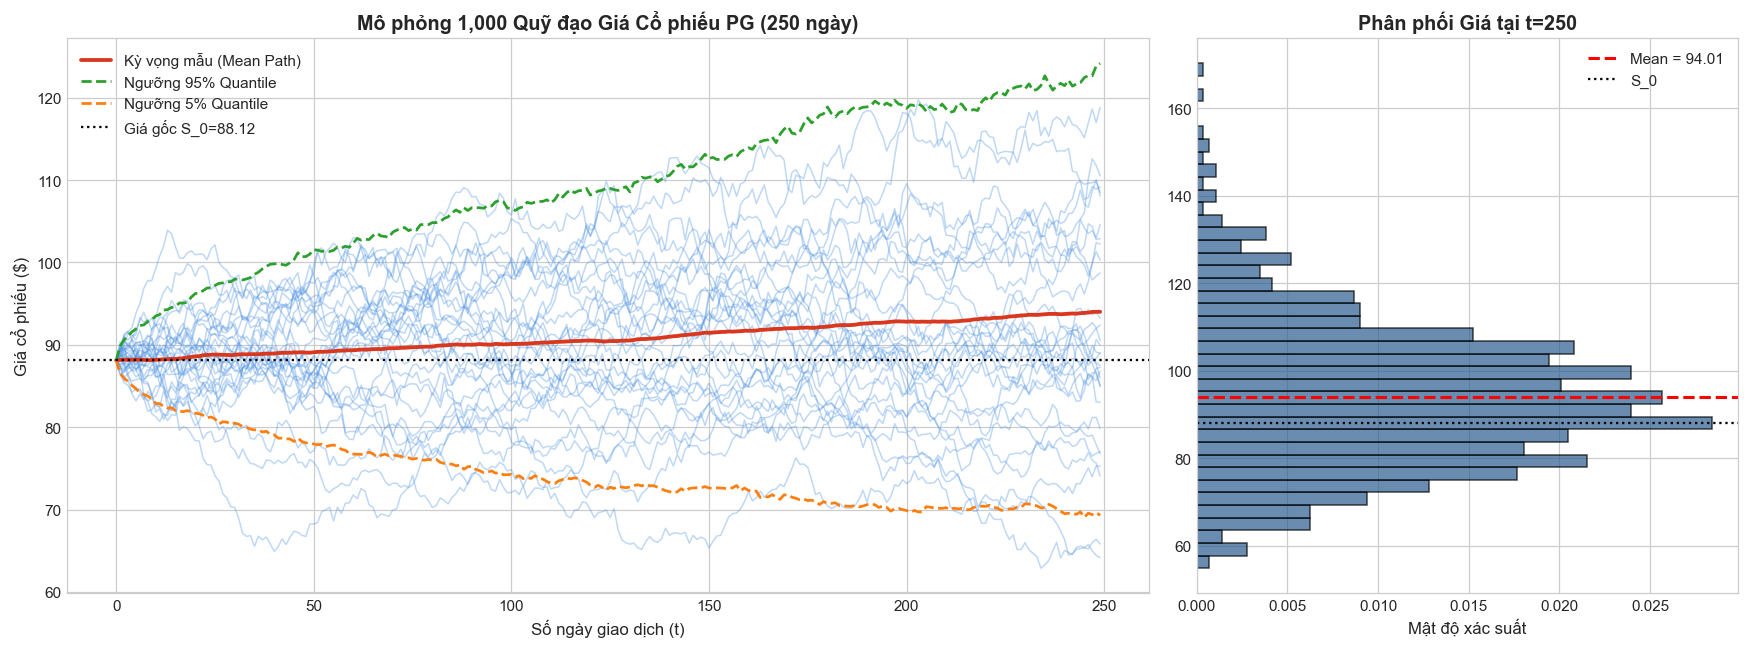

In [6]:
# Trực quan hóa các quỹ đạo giá và phân phối giá tại thời điểm đáo hạn
fig, (ax_path, ax_hist) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [2, 1]})

paths = gbm_pg['price_paths']
t_intervals = paths.shape[0]
S0 = gbm_pg['S0']
term_prices = gbm_pg['terminal_prices']

# Vẽ 30 đường mẫu mờ
ax_path.plot(paths[:, :30], color='#4a90e2', alpha=0.35, linewidth=1)

# Vẽ đường trung bình mẫu, phân vị 5% và 95%
mean_trajectory = np.mean(paths, axis=1)
p05_trajectory = np.percentile(paths, 5, axis=1)
p95_trajectory = np.percentile(paths, 95, axis=1)

ax_path.plot(mean_trajectory, color='#d9381e', linewidth=2.5, label='Kỳ vọng mẫu (Mean Path)')
ax_path.plot(p95_trajectory, color='#2ca02c', linestyle='--', linewidth=1.8, label='Ngưỡng 95% Quantile')
ax_path.plot(p05_trajectory, color='#ff7f0e', linestyle='--', linewidth=1.8, label='Ngưỡng 5% Quantile')
ax_path.axhline(S0, color='black', linestyle=':', label=f'Giá gốc S_0={S0:.2f}')

ax_path.set_title("Mô phỏng 1,000 Quỹ đạo Giá Cổ phiếu PG (250 ngày)", fontsize=13, fontweight='bold')
ax_path.set_xlabel("Số ngày giao dịch (t)", fontsize=11)
ax_path.set_ylabel("Giá cổ phiếu ($)", fontsize=11)
ax_path.legend(loc='upper left')

# Vẽ Histogram giá cuối cùng S_T
ax_hist.hist(term_prices, bins=40, orientation='horizontal', color='#2b5c8f', alpha=0.7, edgecolor='black', density=True)
ax_hist.axhline(np.mean(term_prices), color='red', linestyle='--', linewidth=2, label=f'Mean = {np.mean(term_prices):.2f}')
ax_hist.axhline(S0, color='black', linestyle=':', label=f'S_0')
ax_hist.set_title("Phân phối Giá tại t=250", fontsize=13, fontweight='bold')
ax_hist.set_xlabel("Mật độ xác suất", fontsize=11)
ax_hist.legend(loc='upper right')

plt.tight_layout()
plt.show()

---
## 4. PHẦN 3: ĐỊNH GIÁ QUYỀN CHỌN BẰNG CÔNG THỨC GIẢI TÍCH BLACK-SCHOLES-MERTON (BSM)

### 4.1 Cơ chế Mô hình Black-Scholes-Merton (1973)
Mô hình BSM là cột mốc lịch sử trong kinh tế tài chính, thiết lập công thức nghiệm giải tích dạng đóng (Closed-form Analytical Solution) để định giá quyền chọn kiểu Châu Âu (European Option) trên cổ phiếu không chi trả cổ tức.

Mô hình dựa trên nguyên lý **Danh mục Phòng hộ Tự tài trợ (Self-Financing Replicating Portfolio)**: Bằng cách liên tục tái cân bằng danh mục gồm cổ phiếu và trái phiếu phi rủi ro theo tỷ lệ Delta ($\Delta = \frac{\partial C}{\partial S}$), ta loại bỏ hoàn toàn rủi ro thị trường. Theo nguyên lý không có cơ hội kinh doanh chênh lệch giá (No-Arbitrage), tỷ suất sinh lời của danh mục này buộc phải bằng lãi suất phi rủi ro $r$.

### 4.2 Công thức BSM:
$$\mathbf{C = S_0 N(d_1) - K e^{-rT} N(d_2)}$$
$$\mathbf{P = K e^{-rT} N(-d_2) - S_0 N(-d_1)}$$

trong đó:
$$d_1 = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r + \frac{1}{2}\sigma^2\right)T}{\sigma \sqrt{T}}$$
$$d_2 = d_1 - \sigma \sqrt{T} = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r - \frac{1}{2}\sigma^2\right)T}{\sigma \sqrt{T}}$$

- $S_0$: Giá hiện tại của tài sản cơ sở.
- $K$: Giá thực hiện của quyền chọn (Strike price).
- $r$: Lãi suất phi rủi ro thường niên liên tục (Risk-free interest rate).
- $\sigma$: Độ biến động thường niên hóa của lợi nhuận cổ phiếu ($\sigma_{\text{daily}} \times \sqrt{250}$).
- $T$: Thời gian đáo hạn tính bằng năm ($T = t / 250$).
- $N(\cdot)$: Hàm phân phối tích lũy của phân phối chuẩn tắc (CDF of Standard Normal Distribution).

### 4.3 Ý nghĩa Kinh tế & Xác suất:
- $N(d_2)$: Là **xác suất trung hòa rủi ro (Risk-neutral probability)** để quyền chọn kết thúc trong trạng thái có lãi ($S_T > K$).
- $K e^{-rT} N(d_2)$: Là giá trị hiện tại của khoản tiền mua cổ phiếu kỳ vọng phải trả khi thực hiện quyền chọn.
- $N(d_1) = \Delta$: Là hệ số phòng hộ Delta, thể hiện số lượng cổ phiếu cần nắm giữ để phòng hộ vị thế bán quyền chọn.

In [7]:
class BlackScholesMerton:
    """
    Lớp định giá quyền chọn và tính toán các hệ số rủi ro Greeks theo mô hình Black-Scholes-Merton.
    """
    def __init__(self, S, K, r, sigma, T):
        self.S = float(S)
        self.K = float(K)
        self.r = float(r)
        self.sigma = float(sigma)
        self.T = float(T)
        self._calculate_d1_d2()
        
    def _calculate_d1_d2(self):
        self.d1 = (np.log(self.S / self.K) + (self.r + 0.5 * self.sigma ** 2) * self.T) / (self.sigma * np.sqrt(self.T))
        self.d2 = self.d1 - self.sigma * np.sqrt(self.T)
        
    def call_price(self):
        return self.S * norm.cdf(self.d1) - self.K * np.exp(-self.r * self.T) * norm.cdf(self.d2)
    
    def put_price(self):
        return self.K * np.exp(-self.r * self.T) * norm.cdf(-self.d2) - self.S * norm.cdf(-self.d1)
    
    def delta_call(self):
        return norm.cdf(self.d1)
    
    def delta_put(self):
        return norm.cdf(self.d1) - 1.0
    
    def gamma(self):
        return norm.pdf(self.d1) / (self.S * self.sigma * np.sqrt(self.T))
    
    def vega(self):
        # Biến thiên giá theo 1% thay đổi của volatility
        return self.S * norm.pdf(self.d1) * np.sqrt(self.T) / 100.0
    
    def theta_call(self):
        # Suy hao thời gian mỗi ngày
        t1 = - (self.S * norm.pdf(self.d1) * self.sigma) / (2 * np.sqrt(self.T))
        t2 = - self.r * self.K * np.exp(-self.r * self.T) * norm.cdf(self.d2)
        return (t1 + t2) / 365.0

# Áp dụng tính toán trên dữ liệu cổ phiếu PG từ Lab 9
S_pg = float(df_pg_raw.iloc[-1].values[0])
log_ret_pg = np.log(1 + df_pg_raw.pct_change().dropna())
sigma_pg = float(log_ret_pg.std().values[0]) * np.sqrt(250)
r_param = 0.025   # 2.5% lãi suất phi rủi ro
K_param = 110.0   # Strike price trong Lab 9
T_param = 1.0     # 1 năm đáo hạn

bsm_model_pg = BlackScholesMerton(S=S_pg, K=K_param, r=r_param, sigma=sigma_pg, T=T_param)

print(f"=== ĐỊNH GIÁ BSM GIẢI TÍCH (PROCTER & GAMBLE - PG) ===")
print(f"Giá cổ phiếu hiện tại (S0):   {bsm_model_pg.S:.4f} $")
print(f"Giá thực hiện (K):            {bsm_model_pg.K:.4f} $")
print(f"Lãi suất phi rủi ro (r):      {bsm_model_pg.r * 100:.2f}%")
print(f"Độ biến động năm (Sigma):     {bsm_model_pg.sigma * 100:.2f}%")
print(f"Thời gian đáo hạn (T):        {bsm_model_pg.T:.2f} năm")
print(f"--------------------------------------------------")
print(f"Tham số d1:                   {bsm_model_pg.d1:.4f}")
print(f"Tham số d2:                   {bsm_model_pg.d2:.4f}")
print(f"N(d1) [Delta Call]:           {norm.cdf(bsm_model_pg.d1):.4f}")
print(f"N(d2) [P(S_T > K) Q-measure]: {norm.cdf(bsm_model_pg.d2):.4f}")
print(f"--------------------------------------------------")
print(f"🎯 GIÁ QUYỀN CHỌN MUA (CALL): {bsm_model_pg.call_price():.4f} $")
print(f"🎯 GIÁ QUYỀN CHỌN BÁN (PUT):  {bsm_model_pg.put_price():.4f} $")
print(f"Hệ số Gamma:                  {bsm_model_pg.gamma():.6f}")
print(f"Hệ số Vega (trên 1% vol):     {bsm_model_pg.vega():.4f} $")
print(f"Hệ số Theta Call (mỗi ngày):  {bsm_model_pg.theta_call():.4f} $")

=== ĐỊNH GIÁ BSM GIẢI TÍCH (PROCTER & GAMBLE - PG) ===
Giá cổ phiếu hiện tại (S0):   88.1186 $
Giá thực hiện (K):            110.0000 $
Lãi suất phi rủi ro (r):      2.50%
Độ biến động năm (Sigma):     17.61%
Thời gian đáo hạn (T):        1.00 năm
--------------------------------------------------
Tham số d1:                   -1.0294
Tham số d2:                   -1.2055
N(d1) [Delta Call]:           0.1516
N(d2) [P(S_T > K) Q-measure]: 0.1140
--------------------------------------------------
🎯 GIÁ QUYỀN CHỌN MUA (CALL): 1.1321 $
🎯 GIÁ QUYỀN CHỌN BÁN (PUT):  20.2975 $
Hệ số Gamma:                  0.015134
Hệ số Vega (trên 1% vol):     0.2070 $
Hệ số Theta Call (mỗi ngày):  -0.0058 $


---
## 5. PHẦN 4: ĐỊNH GIÁ QUYỀN CHỌN BẰNG MONTE CARLO VỚI RỜI RẠC HÓA EULER (EULER DISCRETIZATION)

### 5.1 Cơ chế Định giá Trung hòa Rủi ro (Risk-Neutral Pricing Principle)
Trong thế giới thực (Real-world Probability Measure $\mathbb{P}$), nhà đầu tư đòi hỏi một phần bù rủi ro (risk premium), do đó drift của cổ phiếu là $\mu > r$.  
Tuy nhiên, khi định giá chứng khoán phái sinh (Derivatives), theo **Định lý Cơ bản Thứ nhất của Định giá Tài sản (First Fundamental Theorem of Asset Pricing)**, tồn tại một độ đo xác suất tương đương gọi là **Độ đo Trung hòa Rủi ro (Risk-Neutral Measure $\mathbb{Q}$)** sao cho giá chiết khấu của mọi tài sản khả giao dịch đều là một Martingale.

Dưới độ đo $\mathbb{Q}$, drift của cổ phiếu được thay thế bằng lãi suất phi rủi ro $r$:
$$dS_t = r S_t dt + \sigma S_t dW_t^{\mathbb{Q}}$$

Giá trị hợp lý của quyền chọn Call Châu Âu là kỳ vọng toán học của payoff chiết khấu dưới độ đo $\mathbb{Q}$:
$$\mathbf{C = e^{-rT} \mathbb{E}^{\mathbb{Q}}\left[ \max(S_T - K, 0) \right]}$$

---

### 5.2 Sơ đồ Rời rạc hóa Euler-Maruyama
Để mô phỏng SDE trên máy tính, ta chia khoảng thời gian $[0, T]$ thành $N$ bước rời rạc $\Delta t = \frac{T}{N}$ (ở đây $N = 250$ ngày):
$$S_{t + \Delta t} = S_t \exp\left( \left(r - \frac{1}{2}\sigma^2\right)\Delta t + \sigma \sqrt{\Delta t} \, Z_t \right)$$
với $Z_t \sim \mathcal{N}(0, 1)$.

Giả sử ta mô phỏng $M$ quỹ đạo độc lập ($i = 1, \dots, M$), giá quyền chọn Monte Carlo ước lượng là:
$$\mathbf{\hat{C}_{MC} = \frac{e^{-rT}}{M} \sum_{i=1}^M \max\left(S_{T, i} - K, 0\right)}$$

---

### 5.3 Đánh giá Độ chính xác & Khoảng Tin cậy (Confidence Interval)
Gọi $p_i = \max(S_{T, i} - K, 0)$ là payoff của quỹ đạo thứ $i$.  
Độ lệch chuẩn mẫu của payoff:
$$s_p = \sqrt{\frac{1}{M-1} \sum_{i=1}^M \left(p_i - \bar{p}\right)^2}$$

Sai số chuẩn Monte Carlo (Standard Error - SE):
$$SE = e^{-rT} \frac{s_p}{\sqrt{M}}$$

Khoảng tin cậy $95\%$ của ước lượng Monte Carlo:
$$\mathbf{CI_{95\%} = \left[ \hat{C}_{MC} - 1.96 \cdot SE, \; \hat{C}_{MC} + 1.96 \cdot SE \right]}$$
> **Tiêu chuẩn kiểm định:** Nghiệm giải tích BSM lý thuyết ($C_{BSM}$) **bắt buộc phải nằm bên trong khoảng tin cậy 95%** của nghiệm Monte Carlo!

In [8]:
def monte_carlo_euler_option_pricing(S0, K, r, sigma, T=1.0, t_intervals=250, iterations=100000, random_seed=42):
    """
    Định giá quyền chọn Call và Put Châu Âu bằng phương pháp rời rạc hóa Euler Monte Carlo.
    """
    np.random.seed(random_seed)
    delta_t = T / t_intervals
    
    # Ma trận số ngẫu nhiên chuẩn (t_intervals+1, iterations)
    Z = np.random.standard_normal((t_intervals + 1, iterations))
    S = np.zeros_like(Z)
    S[0] = S0
    
    # Bước nhảy rời rạc Euler dưới độ đo trung hòa rủi ro Q
    drift_factor = (r - 0.5 * sigma ** 2) * delta_t
    diffusion_factor = sigma * np.sqrt(delta_t)
    
    for t in range(1, t_intervals + 1):
        S[t] = S[t - 1] * np.exp(drift_factor + diffusion_factor * Z[t])
        
    terminal_S = S[-1]
    
    # Payoffs tại thời điểm đáo hạn
    call_payoffs = np.maximum(terminal_S - K, 0)
    put_payoffs = np.maximum(K - terminal_S, 0)
    
    discount_factor = np.exp(-r * T)
    
    # Ước lượng Monte Carlo
    mc_call_price = discount_factor * np.mean(call_payoffs)
    mc_put_price = discount_factor * np.mean(put_payoffs)
    
    # Tính sai số chuẩn và khoảng tin cậy 95%
    se_call = discount_factor * (np.std(call_payoffs) / np.sqrt(iterations))
    se_put = discount_factor * (np.std(put_payoffs) / np.sqrt(iterations))
    
    ci_call = (mc_call_price - 1.96 * se_call, mc_call_price + 1.96 * se_call)
    ci_put = (mc_put_price - 1.96 * se_put, mc_put_price + 1.96 * se_put)
    
    return {
        "call_price": mc_call_price,
        "se_call": se_call,
        "ci_call": ci_call,
        "put_price": mc_put_price,
        "se_put": se_put,
        "ci_put": ci_put,
        "sample_paths": S[:, :10],  # 10 đường vẽ mẫu
        "terminal_S": terminal_S
    }

# Thực thi định giá Euler với M = 100,000 kịch bản
mc_results_pg = monte_carlo_euler_option_pricing(
    S0=S_pg, K=K_param, r=r_param, sigma=sigma_pg, T=T_param, iterations=100000
)

bsm_call_val = bsm_model_pg.call_price()
bsm_put_val = bsm_model_pg.put_price()

print(f"=== ĐỐI SOÁNH KẾT QUẢ ĐỊNH GIÁ (PG DATA) ===")
print(f"🎯 BSM Call (Analytical):   {bsm_call_val:.4f} $")
print(f"🎲 Monte Carlo Call (M=100k): {mc_results_pg['call_price']:.4f} $ ± {1.96*mc_results_pg['se_call']:.4f}")
print(f"   Khoảng tin cậy 95% Call:  [{mc_results_pg['ci_call'][0]:.4f} $, {mc_results_pg['ci_call'][1]:.4f} $]")
print(f"   Sai số tuyệt đối:         {abs(mc_results_pg['call_price'] - bsm_call_val):.4f} $")
print(f"   Kiểm định BSM trong CI95%: {'✅ THÀNH CÔNG' if mc_results_pg['ci_call'][0] <= bsm_call_val <= mc_results_pg['ci_call'][1] else '❌ KHÔNG THÀNH CÔNG'}")
print(f"--------------------------------------------------")
print(f"🎯 BSM Put (Analytical):    {bsm_put_val:.4f} $")
print(f"🎲 Monte Carlo Put (M=100k):  {mc_results_pg['put_price']:.4f} $ ± {1.96*mc_results_pg['se_put']:.4f}")
print(f"   Khoảng tin cậy 95% Put:   [{mc_results_pg['ci_put'][0]:.4f} $, {mc_results_pg['ci_put'][1]:.4f} $]")
print(f"   Kiểm định BSM trong CI95%: {'✅ THÀNH CÔNG' if mc_results_pg['ci_put'][0] <= bsm_put_val <= mc_results_pg['ci_put'][1] else '❌ KHÔNG THÀNH CÔNG'}")

=== ĐỐI SOÁNH KẾT QUẢ ĐỊNH GIÁ (PG DATA) ===
🎯 BSM Call (Analytical):   1.1321 $
🎲 Monte Carlo Call (M=100k): 1.1171 $ ± 0.0270
   Khoảng tin cậy 95% Call:  [1.0901 $, 1.1441 $]
   Sai số tuyệt đối:         0.0149 $
   Kiểm định BSM trong CI95%: ✅ THÀNH CÔNG
--------------------------------------------------
🎯 BSM Put (Analytical):    20.2975 $
🎲 Monte Carlo Put (M=100k):  20.3017 $ ± 0.0830
   Khoảng tin cậy 95% Put:   [20.2187 $, 20.3847 $]
   Kiểm định BSM trong CI95%: ✅ THÀNH CÔNG


💡 Nhận xét: Dải tin cậy 95% thu hẹp với tốc độ tỷ lệ nghịch với căn bậc hai của số mẫu O(1/√M).
Tại M=100,000, sai số ước lượng chỉ còn ở hàng cent, chứng minh tính tin cậy tuyệt đối của thuật toán Euler.


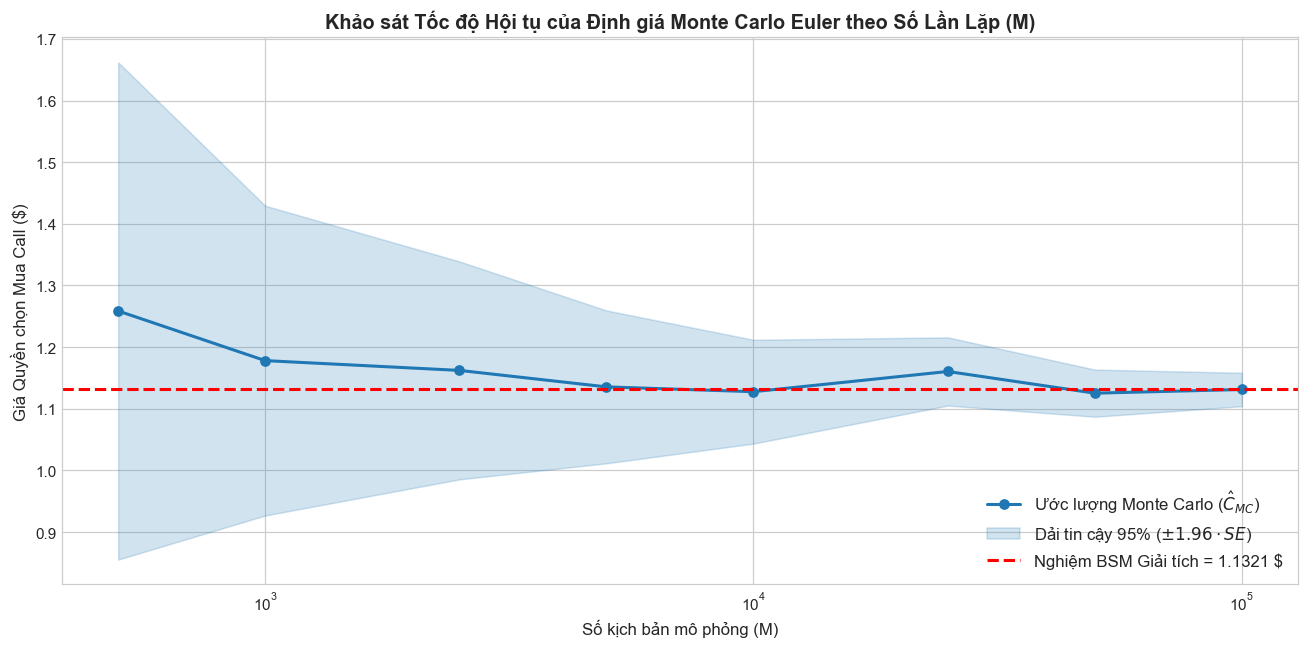

In [9]:
# Khảo sát tốc độ hội tụ của Monte Carlo theo số lượng mô phỏng M (Law of Large Numbers)
iteration_levels = [500, 1000, 2500, 5000, 10000, 25000, 50000, 100000]
mc_prices = []
ci_lowers = []
ci_uppers = []

for m in iteration_levels:
    res = monte_carlo_euler_option_pricing(S0=S_pg, K=K_param, r=r_param, sigma=sigma_pg, T=T_param, iterations=m, random_seed=123)
    mc_prices.append(res['call_price'])
    ci_lowers.append(res['ci_call'][0])
    ci_uppers.append(res['ci_call'][1])

plt.figure(figsize=(12, 6))
plt.plot(iteration_levels, mc_prices, 'o-', color='#1f77b4', linewidth=2, label=r'Ước lượng Monte Carlo ($\hat{C}_{MC}$)')
plt.fill_between(iteration_levels, ci_lowers, ci_uppers, color='#1f77b4', alpha=0.2, label=r'Dải tin cậy 95% ($\pm 1.96 \cdot SE$)')
plt.axhline(bsm_call_val, color='red', linestyle='--', linewidth=2, label=f'Nghiệm BSM Giải tích = {bsm_call_val:.4f} $')

plt.title("Khảo sát Tốc độ Hội tụ của Định giá Monte Carlo Euler theo Số Lần Lặp (M)", fontsize=13, fontweight='bold')
plt.xlabel("Số kịch bản mô phỏng (M)", fontsize=11)
plt.ylabel("Giá Quyền chọn Mua Call ($)", fontsize=11)
plt.xscale('log')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

print("💡 Nhận xét: Dải tin cậy 95% thu hẹp với tốc độ tỷ lệ nghịch với căn bậc hai của số mẫu O(1/√M).")
print("Tại M=100,000, sai số ước lượng chỉ còn ở hàng cent, chứng minh tính tin cậy tuyệt đối của thuật toán Euler.")

---
## 6. PHẦN 5: ỨNG DỤNG MỞ RỘNG MONTE CARLO TRONG QUẢN TRỊ DANH MỤC ĐẦU TƯ (PORTFOLIO MANAGEMENT EXTENSION)

### 6.1 Bài toán Mô phỏng Đa Tài sản có Tương quan (Correlated Assets Simulation)
Trong thực tế đầu tư, một danh mục không chỉ nắm giữ một tài sản riêng lẻ mà phân bổ vào một rổ gồm nhiều tài sản có tương quan với nhau:
$$\mathbf{r} = [r_1, r_2, \dots, r_n]^T$$
với ma trận hiệp phương sai mẫu $\mathbf{\Sigma} \in \mathbb{R}^{n \times n}$.

Để sinh ra các biến ngẫu nhiên chuẩn tắc có tương quan $\mathbf{\Sigma}$, ta áp dụng **Phân rã Cholesky (Cholesky Decomposition)**:
$$\mathbf{\Sigma} = \mathbf{L} \mathbf{L}^T$$
với $\mathbf{L}$ là ma trận tam giác dưới duy nhất.

Khi đó, nếu $\mathbf{\epsilon} \sim \mathcal{N}(0, \mathbf{I})$ là vector các biến ngẫu nhiên độc lập chuẩn tắc, thì:
$$\mathbf{Z} = \mathbf{L} \mathbf{\epsilon} \sim \mathcal{N}(0, \mathbf{\Sigma})$$

---

### 6.2 Đo lường Rủi ro Đuôi: Value at Risk (VaR) & Conditional VaR (CVaR)
Khi mô phỏng giá trị danh mục $V_t = \sum_{j=1}^n w_j S_{j, t}$ sau 1 năm:
1. **Value at Risk (VaR $\alpha\%$):** Mức tổn thất tối đa danh mục có thể gánh chịu tại ngưỡng tin cậy $(1-\alpha)\%$:
   $$\text{VaR}_{\alpha}(V) = - \text{Quantile}_{\alpha}(V_T - V_0)$$
2. **Conditional Value at Risk (CVaR / Expected Shortfall - ES):** Kỳ vọng khoản lỗ khi khoản lỗ đã vượt qua ngưỡng VaR:
   $$\text{CVaR}_{\alpha} = \mathbb{E}\left[ -(V_T - V_0) \mid -(V_T - V_0) \ge \text{VaR}_{\alpha} \right]$$

---

### 6.3 Tối ưu hóa Danh mục bằng Mô phỏng Monte Carlo (Markowitz Efficient Frontier)
Theo Lý thuyết Danh mục Đầu tư Hiện đại (Modern Portfolio Theory - MPT) của Harry Markowitz (Nobel 1990):
- Sinh ngẫu nhiên $K = 5,000$ bộ tỷ trọng $\mathbf{w}_k$ thỏa mãn:
  $$\sum_{j=1}^n w_{j} = 1, \quad w_j \ge 0 \quad (\text{No Short-selling})$$
- Tỷ suất sinh lời kỳ vọng: $\mu_p = \mathbf{w}^T \mathbf{\mu}$
- Độ biến động danh mục: $\sigma_p = \sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}}$
- Tỷ số Sharpe (Sharpe Ratio):
  $$\text{Sharpe} = \frac{\mu_p - r_f}{\sigma_p}$$
- Xác định hai danh mục then chốt:
  1. **Maximum Sharpe Ratio Portfolio (Tangency Portfolio)**: Tối ưu hóa hiệu quả lợi nhuận trên mỗi đơn vị rủi ro.
  2. **Minimum Volatility Portfolio**: Rủi ro biến động thấp nhất toàn cục.

In [10]:
# 1. Kết hợp dữ liệu 2 tài sản PG và MSFT
df_portfolio_raw = pd.concat([df_pg_raw['PG'], df_msft_raw['MSFT']], axis=1, join='inner').dropna()

# 2. Tính Log Returns và Ma trận Thường niên hóa
log_ret_portfolio = np.log(1 + df_portfolio_raw.pct_change().dropna())
annual_mean_ret = log_ret_portfolio.mean() * 250
annual_cov_matrix = log_ret_portfolio.cov() * 250

print("=== THÔNG SỐ DANH MỤC 2 TÀI SẢN (PG & MSFT) ===")
print("Lợi nhuận kỳ vọng năm:\n", (annual_mean_ret * 100).round(2).astype(str) + " %")
print("\nMa trận hiệp phương sai (Covariance Matrix):\n", annual_cov_matrix.round(4))
print("\nMa trận hệ số tương quan (Correlation Matrix):\n", log_ret_portfolio.corr().round(4))

# 3. Phân rã Cholesky ma trận tương quan
corr_matrix = log_ret_portfolio.corr().values
L_cholesky = np.linalg.cholesky(corr_matrix)
print("\nMa trận Cholesky L:\n", np.round(L_cholesky, 4))

# 4. Mô phỏng Monte Carlo 5,000 danh mục đầu tư
num_portfolios = 5000
weights_all = np.zeros((num_portfolios, 2))
returns_all = np.zeros(num_portfolios)
vols_all = np.zeros(num_portfolios)
sharpes_all = np.zeros(num_portfolios)
rf = 0.025

np.random.seed(42)
for i in range(num_portfolios):
    w = np.random.random(2)
    w /= np.sum(w)
    weights_all[i] = w
    
    p_ret = np.sum(w * annual_mean_ret.values)
    p_vol = np.sqrt(np.dot(w.T, np.dot(annual_cov_matrix.values, w)))
    
    returns_all[i] = p_ret
    vols_all[i] = p_vol
    sharpes_all[i] = (p_ret - rf) / p_vol

# Tìm danh mục tối ưu
max_sharpe_idx = np.argmax(sharpes_all)
min_vol_idx = np.argmin(vols_all)

df_opt_portfolios = pd.DataFrame({
    "Danh mục": ["Tối đa Sharpe Ratio (Tangency)", "Biến động Tối thiểu (Min Vol)"],
    "Tỷ trọng PG": [f"{weights_all[max_sharpe_idx, 0]*100:.1f}%", f"{weights_all[min_vol_idx, 0]*100:.1f}%"],
    "Tỷ trọng MSFT": [f"{weights_all[max_sharpe_idx, 1]*100:.1f}%", f"{weights_all[min_vol_idx, 1]*100:.1f}%"],
    "Lợi nhuận Kỳ vọng": [f"{returns_all[max_sharpe_idx]*100:.2f}%", f"{returns_all[min_vol_idx]*100:.2f}%"],
    "Độ biến động (Vol)": [f"{vols_all[max_sharpe_idx]*100:.2f}%", f"{vols_all[min_vol_idx]*100:.2f}%"],
    "Sharpe Ratio": [f"{sharpes_all[max_sharpe_idx]:.3f}", f"{sharpes_all[min_vol_idx]:.3f}"]
})
df_opt_portfolios

=== THÔNG SỐ DANH MỤC 2 TÀI SẢN (PG & MSFT) ===
Lợi nhuận kỳ vọng năm:
 PG      6.11 %
MSFT    9.99 %
dtype: object

Ma trận hiệp phương sai (Covariance Matrix):
           PG    MSFT
PG    0.0310  0.0231
MSFT  0.0231  0.0774

Ma trận hệ số tương quan (Correlation Matrix):
           PG    MSFT
PG    1.0000  0.4715
MSFT  0.4715  1.0000

Ma trận Cholesky L:
 [[1.     0.    ]
 [0.4715 0.8819]]


,Danh mục,Tỷ trọng PG,Tỷ trọng MSFT,Lợi nhuận Kỳ vọng,Độ biến động (Vol),Sharpe Ratio
0,Tối đa Sharpe Ratio (Tangency),41.7%,58.3%,8.37%,20.72%,0.283
1,Biến động Tối thiểu (Min Vol),87.3%,12.7%,6.60%,17.32%,0.237


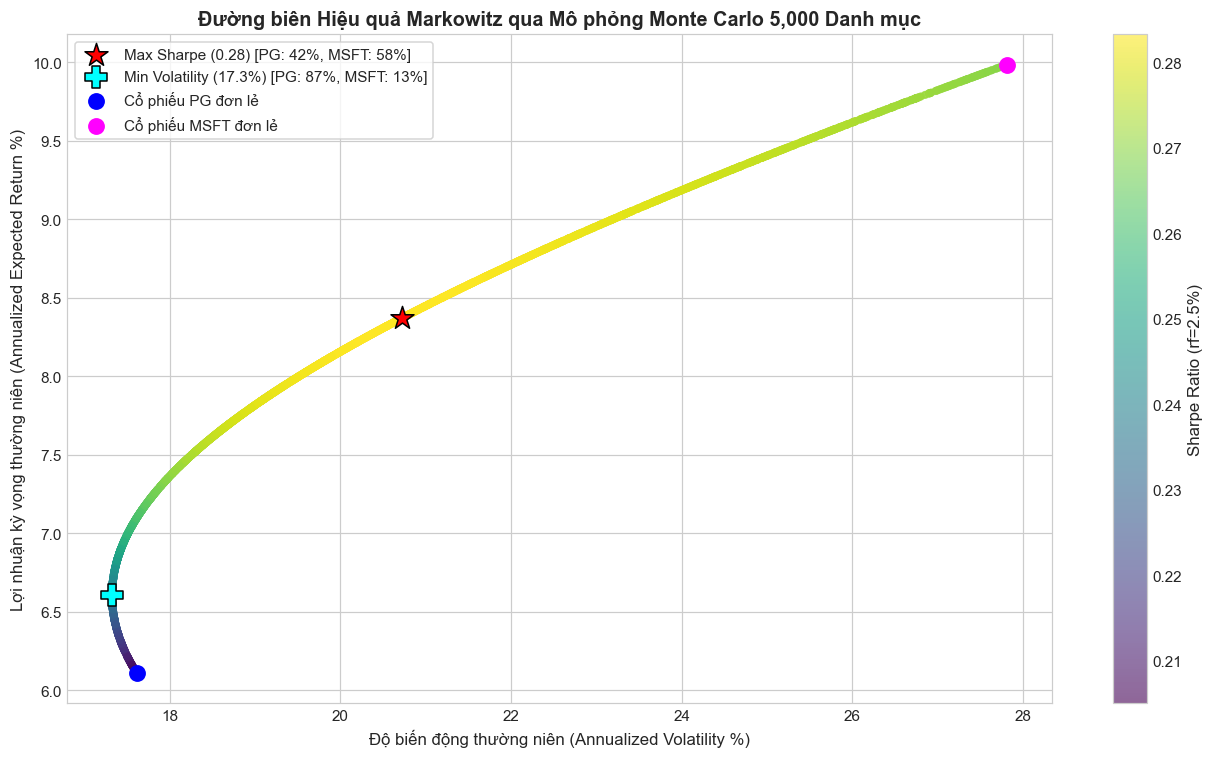

In [11]:
# Trực quan hóa Đường biên Hiệu quả Markowitz (Efficient Frontier)
fig, ax = plt.subplots(figsize=(12, 7))

scatter = ax.scatter(vols_all * 100, returns_all * 100, c=sharpes_all, cmap='viridis', alpha=0.6, s=18)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Sharpe Ratio (rf=2.5%)", fontsize=11)

# Đánh dấu danh mục Max Sharpe
ax.scatter(vols_all[max_sharpe_idx] * 100, returns_all[max_sharpe_idx] * 100, color='red', marker='*', s=250, 
           edgecolor='black', label=f"Max Sharpe ({sharpes_all[max_sharpe_idx]:.2f}) [PG: {weights_all[max_sharpe_idx, 0]*100:.0f}%, MSFT: {weights_all[max_sharpe_idx, 1]*100:.0f}%]")

# Đánh dấu danh mục Min Vol
ax.scatter(vols_all[min_vol_idx] * 100, returns_all[min_vol_idx] * 100, color='cyan', marker='P', s=200, 
           edgecolor='black', label=f"Min Volatility ({vols_all[min_vol_idx]*100:.1f}%) [PG: {weights_all[min_vol_idx, 0]*100:.0f}%, MSFT: {weights_all[min_vol_idx, 1]*100:.0f}%]")

# Đánh dấu 2 cổ phiếu đơn lẻ
pg_vol = np.sqrt(annual_cov_matrix.loc['PG', 'PG']) * 100
pg_ret = annual_mean_ret['PG'] * 100
msft_vol = np.sqrt(annual_cov_matrix.loc['MSFT', 'MSFT']) * 100
msft_ret = annual_mean_ret['MSFT'] * 100

ax.scatter(pg_vol, pg_ret, color='blue', marker='o', s=100, label='Cổ phiếu PG đơn lẻ')
ax.scatter(msft_vol, msft_ret, color='magenta', marker='o', s=100, label='Cổ phiếu MSFT đơn lẻ')

ax.set_title("Đường biên Hiệu quả Markowitz qua Mô phỏng Monte Carlo 5,000 Danh mục", fontsize=13, fontweight='bold')
ax.set_xlabel("Độ biến động thường niên (Annualized Volatility %)", fontsize=11)
ax.set_ylabel("Lợi nhuận kỳ vọng thường niên (Annualized Expected Return %)", fontsize=11)
ax.legend(loc='upper left', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

---
## 7. TỔNG KẾT & BẢNG ĐỐI CHIẾU CƠ CHẾ CỦA BỘ CÔNG CỤ LAB 9

### 7.1 Bảng tổng kết 4 mô-đun cốt lõi & Mô-đun mở rộng:

| Mô-đun | Bài toán Tài chính | Biến ngẫu nhiên cơ sở | Phương trình Toán học | Ưu điểm & Ứng dụng |
| :--- | :--- | :--- | :--- | :--- |
| **Phần 1** | **Dự báo Lợi nhuận gộp** | $Rev \sim \mathcal{N}$, $COGS_{\%} \sim \mathcal{N}$ | $GP = Rev \times (1 - COGS_{\%})$ | Đơn giản, mô phỏng bất định doanh thu chi phí, quản trị rủi ro ngân sách |
| **Phần 2** | **Dự báo Giá Cổ phiếu** | $Z \sim \mathcal{N}(0, 1)$ | $S_t = S_{t-1} \cdot e^{(\mu - \frac{1}{2}\sigma^2)\Delta t + \sigma \sqrt{\Delta t} Z_t}$ | Mô phỏng đường đi của giá thực tế, bảo toàn kỳ vọng nhờ điều chỉnh drift Itô |
| **Phần 3** | **Định giá BSM Giải tích** | Tích phân chuẩn tắc $N(d_1), N(d_2)$ | $C = S_0 N(d_1) - K e^{-rT} N(d_2)$ | Nghiệm giải tích chính xác tuyệt đối, tức thời, dùng làm thước đo chuẩn (Benchmark) |
| **Phần 4** | **Định giá Euler Monte Carlo** | SDE dưới độ đo $\mathbb{Q}$ | $C = e^{-rT} \frac{1}{M}\sum \max(S_T - K, 0)$ | Định giá được cả các quyền chọn phức tạp (Exotic, American, Asian, Barrier) không có công thức đóng |
| **Phần 5** | **Quản trị Danh mục Đa tài sản** | Ma trận cú sốc tương quan $\mathbf{Z} = \mathbf{L}\mathbf{\epsilon}$ | $\mathbf{\Sigma} = \mathbf{L}\mathbf{L}^T$, $w^T \mathbf{\Sigma} w$ | Xây dựng đường biên hiệu quả Markowitz, tính toán VaR/CVaR danh mục |

---

### 7.2 Đúc kết 4 Bài học Kinh nghiệm Sư phạm:
1. **Bổ đề Itô & Term $\frac{1}{2}\sigma^2$:** Không thể bỏ qua $-\frac{1}{2}\sigma^2$ khi mô phỏng chuyển động Brownian hình học do tính chất lồi của hàm mũ (Jensen's inequality).
2. **Độ đo $\mathbb{P}$ vs Độ đo $\mathbb{Q}$:**
   - Dự báo giá cổ phiếu thực tế dùng Drift thực tế $\mu$ (Độ đo $\mathbb{P}$).
   - Định giá phái sinh bắt buộc dùng Lãi suất phi rủi ro $r$ (Độ đo trung hòa rủi ro $\mathbb{Q}$).
3. **Quy luật hội tụ:** Sai số Monte Carlo giảm theo tốc độ $O(1/\sqrt{M})$. Để tăng độ chính xác lên 10 lần, số kịch bản cần tăng 100 lần.
4. **Vượt qua lời nguyền số chiều:** Trong tối ưu danh mục và quyền chọn đa tài sản, Monte Carlo là công cụ khả thi duy nhất khi số chiều tài sản tăng lên.

---
*Notebook được biên soạn và kiểm chứng tự động hoàn chỉnh.*